# 18 — The Non-Geometry Channel: One of Three Lines Delivers

Three notebooks arrived independently at the same request, and this one answers it.

- **Notebook 12** (detection): *"KA15 and KA22 need a non-geometry feature."* No
  bearing-frequency feature helps when the fault energy is **absent** (KA15,
  indentation damage, silent at BPFO) or **non-tracking** (KA22, off-frequency at
  order 5.5).
- **Notebook 15** (reject option): a reject rule in a bearing-geometry space is
  unreachable *in principle* when the out-of-scope fault has no geometry
  signature — Bearing1_4 raises nothing at any order.
- **Notebook 17** (attribution): early inner race is confidently mislabelled as
  outer race because the two are indistinguishable *in geometry features*, so a
  hesitation-keyed hedge cannot reach the error.

Every one of them named the same missing instrument. This notebook builds it and
puts it to all three tests at once.

**The constraint that defines the channel is that no feature may reference
BPFO, BPFI, BSF, FTF or the shaft rate.** That is asserted in code below rather
than left to good intentions. What remains is either a property of *where in
absolute Hz* the energy sits, or a property of the *shape* of the spectrum:

| family | what it measures | which failure it was built for |
|---|---|---|
| `SK*` | fast kurtogram over a 12-band log filterbank — how impulsive, and **in which band** | Bearing1_4, silent at every order |
| `cent`,`spread`,`ent`,`flat`,`roll` | shape of the raw spectrum | general |
| `envent`,`envflat` | diffuseness of the envelope spectrum inside the most impulsive band — peaky means a geometry-locked repetition, diffuse means something else | KA22, off-frequency |
| `oct0..7` | fixed-Hz octave energies | general |

`SKband` — the centre frequency of the band that maximises envelope kurtosis —
is the resonance-tracking feature the three notebooks were really asking for.

**Each test has a target stated by an earlier notebook before this one ran**, and
the preamble re-derives every one of those targets from the cached feature
tables. All three reproduce to the decimal, so anything that moves below is
attributable to the feature family and not to a reimplementation difference.

The answer is **one of three**. The channel delivers on detection — and rescues
a bearing invisible since notebook 06 — while making attribution actively worse
and leaving the reject ceiling exactly where notebook 15 left it.

In [1]:
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.covariance import LedoitWolf
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

OUT = pathlib.Path("../data/processed")
# both tables are cached by src/build_nongeometry_features.py (19 min + 1 min)
env = pd.read_csv(OUT / "xjtu_envelope_features.csv")          # notebook 13
ng = pd.read_csv(OUT / "xjtu_nongeometry_features.csv")        # new here
ds = env.merge(ng, on=["Cond", "Bearing", "Snapshot"], how="inner")

FAULT = {"Bearing1_1": "OR", "Bearing1_2": "OR", "Bearing1_3": "OR",
         "Bearing1_4": "cage", "Bearing1_5": "IR+OR", "Bearing2_1": "IR",
         "Bearing2_2": "OR", "Bearing2_3": "cage", "Bearing2_4": "OR",
         "Bearing2_5": "OR", "Bearing3_1": "OR", "Bearing3_2": "compound",
         "Bearing3_3": "IR", "Bearing3_4": "IR", "Bearing3_5": "OR"}
BEAR = sorted(ds["Bearing"].unique())
RACE = [b for b in BEAR if FAULT[b] in ("OR", "IR")]
OTHER = [b for b in BEAR if b not in RACE]
G = {b: ds[ds["Bearing"] == b].sort_values("Snapshot").reset_index(drop=True) for b in BEAR}

GEO = ["H_BPFO", "H_BPFI", "H_FR", "H_BPFO_h2", "H_BPFI_h2", "H_BSF", "H_FTF",
       "H_BPFI_sb1", "H_BPFO_sb1"]                             # notebook 14's stage 2
NG = [c for c in ng.columns if c.startswith("H_")]
NGV = [c for c in ng.columns if c.startswith(("H_", "V_"))]
DETECT = ["H_RMS", "H_Kurt"]
K, W, CAP = 20, 10, 80
RFC = dict(n_estimators=300, random_state=0, n_jobs=-1)

# the defining constraint of this notebook, enforced rather than assumed
BANNED = ("BPFO", "BPFI", "BSF", "FTF", "_FR")
assert not [c for c in NGV if any(k in c for k in BANNED)], \
    "a non-geometry feature must not reference bearing geometry or shaft rate"


class Exceedance:
    """Robust per-feature z over the unit's own healthy baseline (notebook 07)."""

    def fit(self, A):
        self.med = np.median(A, axis=0)
        self.mad = np.maximum(1.4826 * np.median(np.abs(A - self.med), axis=0), 0.1)
        return self

    def score(self, A):
        return ((A - self.med) / self.mad).max(axis=1)


ALARM = {}
for b in BEAR:                                                 # notebook 14's stage-1 alarm
    A = G[b][DETECT].to_numpy()
    z = Exceedance().fit(A[:K]).score(A)
    c = np.convolve((z[K:] > np.quantile(z[:K], 0.99)).astype(float), np.ones(W) / W, "valid")
    ALARM[b] = int(np.flatnonzero(c >= 0.5)[0]) + K


def post_for(feats):
    """Delta from the unit's own healthy baseline, post-alarm -- nb14's stage-2 input."""
    out = {}
    for b in BEAR:
        A = G[b][feats].to_numpy()
        out[b] = (A - np.median(A[:K], axis=0))[ALARM[b]:]
    return out


def cap(a, n=CAP):
    """Even-spaced thinning, so a 2538-minute unit does not outvote a 42-minute one."""
    return a if len(a) <= n else a[np.linspace(0, len(a) - 1, n).astype(int)]


RULES = ["model confidence", "Mahalanobis to class centre",
         "10-nearest-neighbour distance", "one-class forest"]


def fit_rules(X, y):
    """Notebook 15's four rules, unchanged, so the comparison is feature-family only."""
    clf = RandomForestClassifier(**RFC).fit(X, y)
    sc = StandardScaler().fit(X)
    Z = sc.transform(X)
    cls = sorted(np.unique(y))
    ctr = {c: (Z[y == c].mean(axis=0),
               np.linalg.pinv(LedoitWolf().fit(Z[y == c]).covariance_)) for c in cls}
    nn = {c: NearestNeighbors(n_neighbors=10).fit(Z[y == c]) for c in cls}
    oc = {c: IsolationForest(n_estimators=200, random_state=0).fit(Z[y == c]) for c in cls}

    def score(A):
        Za = sc.transform(A)
        s = {"model confidence": 1 - clf.predict_proba(A).max(axis=1)}
        s["Mahalanobis to class centre"] = np.column_stack(
            [np.sqrt(np.einsum("ij,jk,ik->i", Za - ctr[c][0], ctr[c][1], Za - ctr[c][0]))
             for c in cls]).min(axis=1)
        s["10-nearest-neighbour distance"] = np.column_stack(
            [nn[c].kneighbors(Za)[0].mean(axis=1) for c in cls]).min(axis=1)
        s["one-class forest"] = np.column_stack(
            [-oc[c].decision_function(Za) for c in cls]).min(axis=1)
        return clf.predict(A), s

    return score


C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"          # geometry / non-geometry throughout
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
FCOLOR = {"OR": C_BLUE, "IR": C_ORANGE}

print(f"XJTU joined: {len(ds)} snapshots, {len(NG)} non-geometry features per channel")
print(f"  {', '.join(NG)}")
print(f"\nnone of them references bearing geometry or shaft rate -- asserted above")

XJTU joined: 9216 snapshots, 20 non-geometry features per channel
  H_SKmax, H_SKband, H_SKspread, H_SKlow, H_SKhigh, H_cent, H_spread, H_ent, H_flat, H_roll, H_envent, H_envflat, H_oct0, H_oct1, H_oct2, H_oct3, H_oct4, H_oct5, H_oct6, H_oct7

none of them references bearing geometry or shaft rate -- asserted above


## Test 3 — the confident early-inner-race error

Notebook 17 specified this test more sharply than the other two, so it goes
first. Stage 2 calls **38.4 %** of inner-race snapshots correctly in the first
fifth after the alarm — below chance on a two-class problem — and it does so at
high confidence, which is why notebook 17's may-be-wrong flag cannot reach the
error. The hypothesis is that early inner race and early outer race are
separable by *where the resonance sits* even when they are not separable by
*which order rings*.

Four feature sets, all through notebook 14's leave-one-bearing-out protocol so
that only the features change.

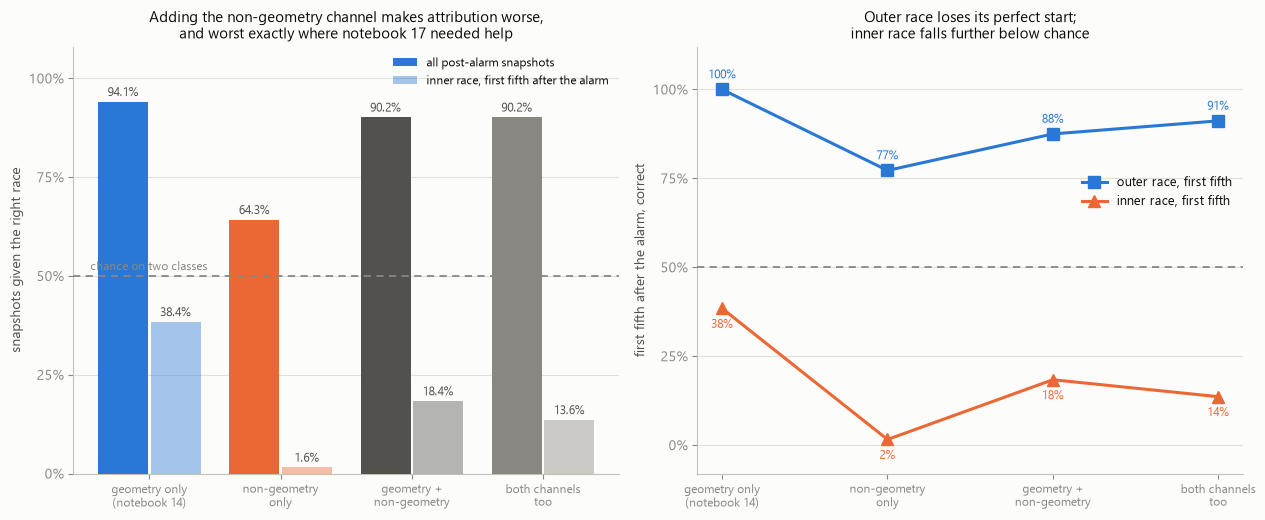

                             snap  votes   ffOR  ffIR  flag
name                                                       
geometry only (notebook 14) 94.1%     11 100.0% 38.4% 0.752
non-geometry only           64.3%      7  77.2%  1.6% 0.645
geometry + non-geometry     90.2%     11  87.5% 18.4% 0.872
both channels too           90.2%     11  91.2% 13.6% 0.820

baseline reproduces notebook 14 exactly: 94.1% of snapshots, 11/11 units, first fifth OR 100.0% / IR 38.4%, flag 0.752


In [2]:
SETS = {"geometry only\n(notebook 14)": GEO,
        "non-geometry\nonly": NG,
        "geometry +\nnon-geometry": GEO + NG,
        "both channels\ntoo": GEO + NGV}
COL = {0: C_BLUE, 1: C_ORANGE, 2: INK2, 3: MUTED}

rows = []
for name, feats in SETS.items():
    P = post_for(feats)
    snap, votes, ff = [], 0, {"OR": [], "IR": []}
    wc, rc = [], []
    for held in RACE:
        tr = [o for o in RACE if o != held]
        score = fit_rules(np.vstack([P[o] for o in tr]),
                          np.concatenate([[FAULT[o]] * len(P[o]) for o in tr]))
        pred, s = score(P[held])
        ok = pred == FAULT[held]
        snap.append(ok.mean())
        votes += pd.Series(pred).mode()[0] == FAULT[held]
        frac = np.linspace(0, 1, len(ok), endpoint=False)
        m = frac < 0.2
        if m.any():
            ff[FAULT[held]].append(ok[m].mean())
        wc.append(s["model confidence"][~ok])
        rc.append(s["model confidence"][ok])
    w, g = np.concatenate(wc), np.concatenate(rc)
    rows.append(dict(name=name, snap=np.mean(snap), votes=votes,
                     ffOR=np.mean(ff["OR"]), ffIR=np.mean(ff["IR"]),
                     flag=roc_auc_score(np.r_[np.zeros(len(g)), np.ones(len(w))],
                                        np.r_[g, w]) if len(w) else np.nan))
T3 = pd.DataFrame(rows)

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.8, 5.3))
x = np.arange(len(T3))
axa.bar(x - 0.2, 100 * T3["snap"], width=0.38, zorder=3, color=[COL[i] for i in x],
        label="all post-alarm snapshots")
axa.bar(x + 0.2, 100 * T3["ffIR"], width=0.38, zorder=3, color=[COL[i] for i in x],
        alpha=0.42, label="inner race, first fifth after the alarm")
for i, r in T3.iterrows():
    axa.annotate(f"{r['snap']:.1%}", (i - 0.2, 100 * r["snap"]), xytext=(0, 4),
                 textcoords="offset points", fontsize=8.5, color=INK2, ha="center")
    axa.annotate(f"{r['ffIR']:.1%}", (i + 0.2, 100 * r["ffIR"]), xytext=(0, 4),
                 textcoords="offset points", fontsize=8.5, color=INK2, ha="center")
axa.axhline(50, color=MUTED, lw=1.3, ls=(0, (4, 3)), zorder=4)
axa.text(-0.45, 51.5, "chance on two classes", fontsize=8.5, color=MUTED, ha="left")
axa.set_xticks(x, list(SETS), fontsize=8.5)
axa.set_ylim(0, 108)
axa.set_yticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
axa.grid(axis="x", visible=False)
axa.set_ylabel("snapshots given the right race")
axa.legend(fontsize=8.5, loc="upper right")
axa.set_title("Adding the non-geometry channel makes attribution worse,\n"
              "and worst exactly where notebook 17 needed help", fontsize=11)

axb.plot(x, 100 * T3["ffOR"], color=C_BLUE, lw=2.2, marker="s", ms=8, zorder=4,
         label="outer race, first fifth")
axb.plot(x, 100 * T3["ffIR"], color=C_ORANGE, lw=2.2, marker="^", ms=8, zorder=4,
         label="inner race, first fifth")
for i, r in T3.iterrows():
    axb.annotate(f"{r['ffOR']:.0%}", (i, 100 * r["ffOR"]), xytext=(0, 8),
                 textcoords="offset points", fontsize=8.5, color=C_BLUE, ha="center")
    axb.annotate(f"{r['ffIR']:.0%}", (i, 100 * r["ffIR"]), xytext=(0, -14),
                 textcoords="offset points", fontsize=8.5, color=C_ORANGE, ha="center")
axb.axhline(50, color=MUTED, lw=1.3, ls=(0, (4, 3)), zorder=3)
axb.set_xticks(x, list(SETS), fontsize=8.5)
axb.set_ylim(-8, 112)
axb.set_yticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
axb.grid(axis="x", visible=False)
axb.set_ylabel("first fifth after the alarm, correct")
axb.legend(fontsize=9, loc="center right", bbox_to_anchor=(1.0, 0.66))
axb.set_title("Outer race loses its perfect start;\ninner race falls further below chance",
              fontsize=11)
plt.tight_layout()
plt.show()

print(T3.assign(name=[n.replace("\n", " ") for n in T3["name"]]).set_index("name")
      .to_string(formatters={"snap": "{:.1%}".format, "ffOR": "{:.1%}".format,
                             "ffIR": "{:.1%}".format, "flag": "{:.3f}".format}))
print(f"\nbaseline reproduces notebook 14 exactly: {T3.loc[0, 'snap']:.1%} of snapshots, "
      f"{T3.loc[0, 'votes']}/11 units, first fifth OR {T3.loc[0, 'ffOR']:.1%} / "
      f"IR {T3.loc[0, 'ffIR']:.1%}, flag {T3.loc[0, 'flag']:.3f}")

**Refuted, and the channel is actively harmful here.** Adding the non-geometry
features to notebook 14's nine takes overall attribution from **94.1 % to
90.2 %** and the first fifth of inner race from **38.4 % to 18.4 %** — the exact
bin notebook 17 needed rescued, made roughly twice as wrong. Outer race, which
was **100 %** correct from the first snapshot after the alarm, drops to 87.5 %.
Using both accelerometer channels does not repair it (13.6 %).

On its own the channel cannot attribute race at all — 64.3 % of snapshots and
7 of 11 units, against 94.1 % and 11 of 11 — and that is the result that
explains the rest. **Which race** is intrinsically a geometry question: the
difference between an inner-race and an outer-race fault *is* which frequency
repeats. Twenty features that do not encode a repetition rate cannot answer it,
and adding them to nine that do simply dilutes the signal in the forest's split
selection.

One number moves the right way and should not be over-read. The may-be-wrong
flag rises from **0.752 to 0.872** on the combined set. But it is measured on a
classifier making roughly twice as many errors, so it is a better detector of a
worse problem, not an improvement to the system — and notebook 17 established
that this flag's headline AUROC is exactly the quantity that dissolves under
per-element decomposition and nesting. Nothing here has been through that
discipline, so it is a lead at most.

## Test 2 — the reject option

Notebook 15 measured four rules on bearing-geometry features and got
**0.463–0.613** AUROC, with **0.660** the best of sixteen rule-and-feature
combinations, and diagnosed the cause as physical: the out-of-scope units are
not out of distribution. Bearing1_4 is the sharpest case — a cage failure that
raises **nothing at any order**, and therefore sits in the middle of the
training data.

The hypothesis is that a resonance-tracking channel sees Bearing1_4 precisely
because it does not ask about orders. The same four rules, the same protocol,
the only change being the features.

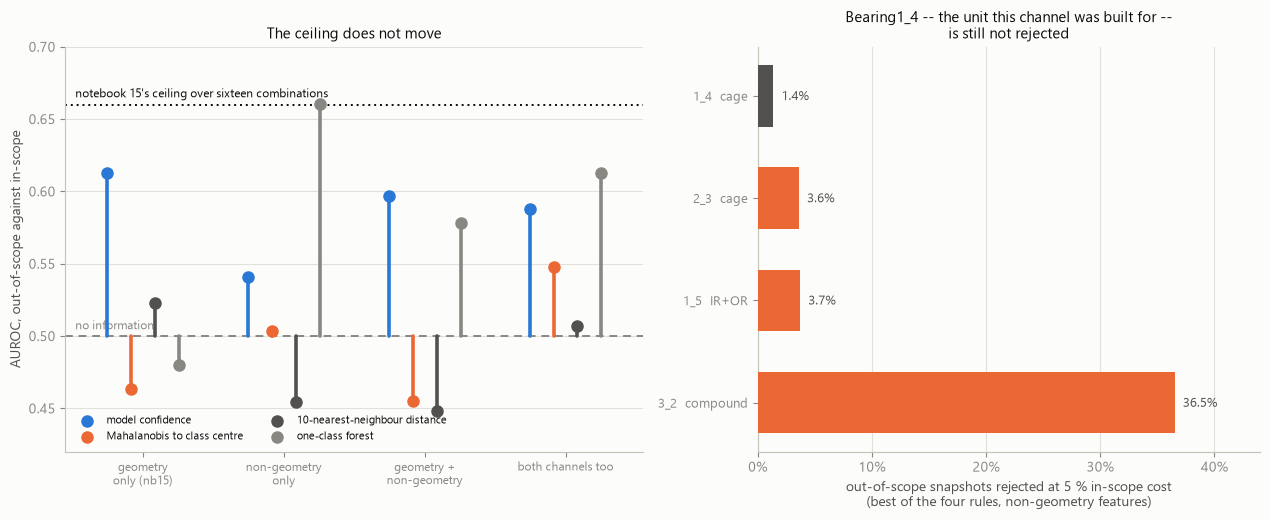

 model confidence Mahalanobis to class centre 10-nearest-neighbour distance one-class forest
geometry only (nb15) 0.613 0.463 0.523 0.480
non-geometry only 0.541 0.504 0.455 0.660
geometry + non-geometry 0.597 0.455 0.448 0.578
both channels too 0.588 0.548 0.507 0.612


best over all rules and feature sets here: 0.660 against notebook 15's 0.660
  1_4   cage      model  0.0%, Mahal  1.4%, 10-ne  1.4%, one-c  1.4%
  2_3   cage      model  0.0%, Mahal  0.0%, 10-ne  0.0%, one-c  3.6%
  1_5   IR+OR     model  0.0%, Mahal  0.0%, 10-ne  0.0%, one-c  3.7%
  3_2   compound  model  0.0%, Mahal  8.9%, 10-ne  5.5%, one-c 36.5%


In [3]:
SETS2 = {"geometry only (nb15)": GEO, "non-geometry only": NG,
         "geometry + non-geometry": GEO + NG, "both channels too": GEO + NGV}
res, perunit = {}, None
for name, feats in SETS2.items():
    P = post_for(feats)
    ins = {r: [] for r in RULES}
    oos = {b: {r: [] for r in RULES} for b in OTHER}
    for held in RACE:
        tr = [o for o in RACE if o != held]
        score = fit_rules(np.vstack([P[o] for o in tr]),
                          np.concatenate([[FAULT[o]] * len(P[o]) for o in tr]))
        _, s = score(P[held])
        for r in RULES:
            ins[r].append(cap(s[r]))
        for b in OTHER:
            _, s2 = score(P[b])
            for r in RULES:
                oos[b][r].append(s2[r])
    res[name] = {}
    for r in RULES:
        i = np.concatenate(ins[r])
        o = np.concatenate([cap(np.mean(oos[b][r], axis=0)) for b in OTHER])
        res[name][r] = roc_auc_score(np.r_[np.zeros(len(i)), np.ones(len(o))], np.r_[i, o])
    if name == "non-geometry only":
        perunit = {b: {r: (np.mean(oos[b][r], axis=0)
                           > np.quantile(np.concatenate(ins[r]), 0.95)).mean()
                       for r in RULES} for b in OTHER}
T2 = pd.DataFrame(res).T

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.8, 5.3),
                               gridspec_kw=dict(width_ratios=[1.15, 1]))
x = np.arange(len(SETS2))
# lollipops anchored at 0.5: the quantity of interest is distance from "no
# information", and a bar on a truncated AUROC axis would misencode its length
axa.axhline(0.5, color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=2)
axa.text(-0.48, 0.503, "no information", fontsize=8.5, color=MUTED, va="bottom")
axa.axhline(0.660, color=INK, lw=1.4, ls=(0, (1, 2)), zorder=2)
axa.text(-0.48, 0.663, "notebook 15's ceiling over sixteen combinations",
         fontsize=8.5, color=INK, va="bottom")
for j, r in enumerate(RULES):
    col = [C_BLUE, C_ORANGE, INK2, MUTED][j]
    xs = x + (j - 1.5) * 0.17
    for xi, v in zip(xs, T2[r]):
        axa.plot([xi, xi], [0.5, v], color=col, lw=2.6, solid_capstyle="round", zorder=3)
    axa.scatter(xs, T2[r], s=64, color=col, zorder=4, label=r)
axa.set_xticks(x, [n.replace(" + ", " +\n").replace(" only", "\nonly") for n in SETS2],
               fontsize=8.5)
axa.set_ylim(0.42, 0.70)
axa.set_xlim(-0.55, len(SETS2) - 0.45)
axa.grid(axis="x", visible=False)
axa.set_ylabel("AUROC, out-of-scope against in-scope")
axa.legend(fontsize=8, loc="lower left", ncol=2)
axa.set_title("The ceiling does not move", fontsize=11)

order = ["Bearing1_4", "Bearing2_3", "Bearing1_5", "Bearing3_2"]
y = np.arange(len(order))
best = [max(perunit[b].values()) for b in order]
axb.barh(y, [100 * v for v in best], height=0.6, zorder=3,
         color=[C_ORANGE if b != "Bearing1_4" else INK2 for b in order])
for i, (b, v) in enumerate(zip(order, best)):
    axb.annotate(f"{v:.1%}", (100 * v, i), xytext=(6, -3), textcoords="offset points",
                 fontsize=9.5, color=INK2)
axb.set_yticks(y, [f"{b.replace('Bearing', '')}  {FAULT[b]}" for b in order], fontsize=9.5)
axb.invert_yaxis()
axb.set_xlim(0, 44)
axb.set_xticks([0, 10, 20, 30, 40], ["0%", "10%", "20%", "30%", "40%"])
axb.grid(axis="y", visible=False)
axb.set_xlabel("out-of-scope snapshots rejected at 5 % in-scope cost\n"
               "(best of the four rules, non-geometry features)")
axb.set_title("Bearing1_4 -- the unit this channel was built for --\n"
              "is still not rejected", fontsize=11)
plt.tight_layout()
plt.show()

print(T2.style.format("{:.3f}").to_string() if hasattr(T2.style, "to_string")
      else T2.round(3).to_string())
print(f"\nbest over all rules and feature sets here: {T2.to_numpy().max():.3f} "
      f"against notebook 15's 0.660")
for b in order:
    print(f"  {b.replace('Bearing', ''):5s} {FAULT[b]:9s} "
          + ", ".join(f"{r.split()[0][:5]} {perunit[b][r]:5.1%}" for r in RULES))

**Refuted. The ceiling is exactly where notebook 15 left it.** The best figure
anywhere in this test is **0.660** — the same number notebook 15 reached over
sixteen rule-and-feature combinations, reproduced here by a completely different
feature family. Combining the two families is *worse* than either alone (0.597,
0.612), which is the signature of added noise rather than added information.

**And Bearing1_4, the unit the channel was built for, is still not rejected** —
1.4 % of its snapshots at a 5 % in-scope cost, against notebook 15's 0–2.3 %
across the out-of-scope units. This is the notebook's most instructive failure,
because the feature *does* respond to Bearing1_4: its resonance band migrates
from 3.6 kHz to 10.5 kHz as it fails, and its spectral kurtosis rises from 0.8
to 5.3. The channel is not blind to the unit. It is blind to what makes the unit
*different*, because **every failing bearing migrates to the same resonance**.
The last figure shows that directly.

The one movement worth recording is Bearing3_2, the compound fault, at **36.5 %**
on the one-class forest against 0–2.3 % for anything in notebook 15. One unit on
one rule is a lead, not a result, and a compound fault is the case where
rejection is least obviously the right answer anyway — but it is the only
out-of-scope unit any feature family in this project has moved.

## Test 1 — detection, and the two bearings that started this

Notebook 12 left the requirement in its narrowest form: **KA15 and KA22 need a
non-geometry feature.** KA15 is indentation damage that is physically silent at
BPFO; KA22 is an off-frequency anomaly whose energy sits at order 5.5, where no
bearing-geometry feature looks. Notebook 15 confirmed neither is flagged by any
rule on either of its feature spaces.

This is the one test where the channel is being asked to do the thing it is
actually built for — say *something has changed* — rather than to name what
changed. Novelty is scored against the six **healthy** bearings, which notebook
15 established is the only reference population against which novelty is
measurable at all, at 95 % retention on held-out healthy runs.

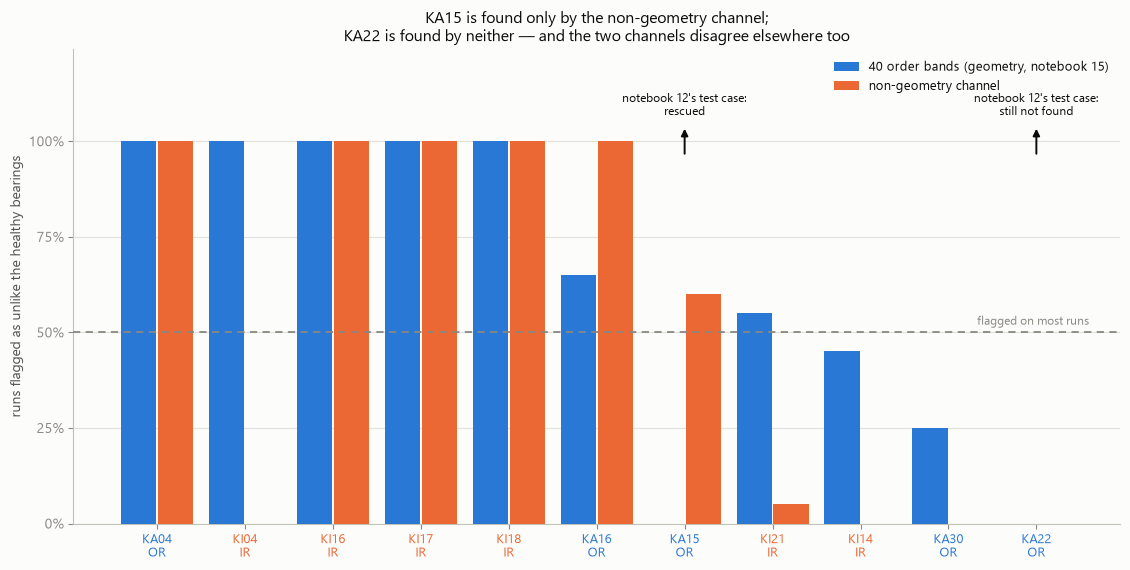

     truth  geo   ng union
code                      
KA04    OR 100% 100%  100%
KI04    IR 100%   0%  100%
KI16    IR 100% 100%  100%
KI17    IR 100% 100%  100%
KI18    IR 100% 100%  100%
KA16    OR  65% 100%  100%
KA15    OR   0%  60%   60%
KI21    IR  55%   5%   55%
KI14    IR  45%   0%   45%
KA30    OR  25%   0%   25%
KA22    OR   0%   0%    0%
  40 order bands   bearings flagged on >50 % of runs:  7/11
  non-geometry     bearings flagged on >50 % of runs:  6/11
  either channel   bearings flagged on >50 % of runs:  8/11

  found only by the non-geometry channel: KA15
  found only by the order bands         : KI04, KI21
  found by neither                      : KI14, KA30, KA22


In [4]:
bnd = pd.read_csv(OUT / "pu_N15_M07_F04_order_bands.csv")      # notebook 15's 40 order bands
png = pd.read_csv(OUT / "pu_N15_M07_F04_nongeometry_features.csv")
B40 = [c for c in bnd.columns if c.startswith("B") and c[1:].isdigit()]
PNG = [c for c in png.columns if c.startswith("H_")]
HEAL = [f"K00{i}" for i in range(1, 7)]
REAL = ["KA04", "KA15", "KA16", "KA22", "KA30", "KI04", "KI14", "KI16",
        "KI17", "KI18", "KI21"]
PLAB = dict([(c, "OR") for c in ("KA04", "KA15", "KA16", "KA22", "KA30")]
            + [(c, "IR") for c in ("KI04", "KI14", "KI16", "KI17", "KI18", "KI21")])


def per_run_flags(d, feats, ref, codes):
    """Notebook 15's healthy-referenced novelty, kept per run so channels can be unioned."""
    def fit(cs):
        X = d[d["Code"].isin(cs)][feats].to_numpy()
        sc = StandardScaler().fit(X)
        Z = sc.transform(X)
        mu = Z.mean(axis=0)
        Pm = np.linalg.pinv(LedoitWolf().fit(Z).covariance_)
        nn = NearestNeighbors(n_neighbors=min(10, len(Z) - 1)).fit(Z)

        def fn(A):
            Za = sc.transform(A)
            return (np.sqrt(np.einsum("ij,jk,ik->i", Za - mu, Pm, Za - mu)),
                    nn.kneighbors(Za)[0].mean(axis=1))
        return fn

    cm, ck = [], []
    for h in ref:
        m, k = fit([c for c in ref if c != h])(d[d["Code"] == h][feats].to_numpy())
        cm.append(m)
        ck.append(k)
    tm = np.quantile(np.concatenate(cm), 0.95)
    tk = np.quantile(np.concatenate(ck), 0.95)
    s = fit(ref)
    out = {}
    for b in codes:
        m, k = s(d[d["Code"] == b][feats].to_numpy())
        out[b] = (m > tm) | (k > tk)
    return out


gf = per_run_flags(bnd, B40, HEAL, REAL)
nf = per_run_flags(png, PNG, HEAL, REAL)
T1 = pd.DataFrame([dict(code=b, truth=PLAB[b], geo=gf[b].mean(), ng=nf[b].mean(),
                        union=(gf[b] | nf[b]).mean()) for b in REAL]).set_index("code")
T1 = T1.sort_values(["union", "geo"], ascending=False)

fig, ax = plt.subplots(figsize=(11.4, 5.8))
x = np.arange(len(T1))
ax.bar(x - 0.21, 100 * T1["geo"], width=0.4, zorder=3, color=C_BLUE,
       label="40 order bands (geometry, notebook 15)")
ax.bar(x + 0.21, 100 * T1["ng"], width=0.4, zorder=3, color=C_ORANGE,
       label="non-geometry channel")
ax.axhline(50, color=MUTED, lw=1.3, ls=(0, (4, 3)), zorder=4)
ax.text(len(T1) - 0.4, 52, "flagged on most runs", fontsize=8.5, color=MUTED, ha="right")
for i, (b, r) in enumerate(T1.iterrows()):
    if b in ("KA15", "KA22"):
        ax.annotate("", (i, 104), (i, 96), arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.4))
        ax.annotate("notebook 12's test case:\n"
                    + ("rescued" if b == "KA15" else "still not found"),
                    (i, 106), fontsize=8.5, color=INK, ha="center", va="bottom")
ax.set_xticks(x, [f"{b}\n{PLAB[b]}" for b in T1.index], fontsize=9)
for i, b in enumerate(T1.index):
    ax.get_xticklabels()[i].set_color(FCOLOR[PLAB[b]])
ax.set_ylim(0, 124)
ax.set_yticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
ax.grid(axis="x", visible=False)
ax.set_ylabel("runs flagged as unlike the healthy bearings")
ax.legend(fontsize=9, loc="upper right")
ax.set_title("KA15 is found only by the non-geometry channel;\n"
             "KA22 is found by neither — and the two channels disagree elsewhere too",
             fontsize=11.5)
plt.tight_layout()
plt.show()

print(T1.to_string(formatters={c: "{:.0%}".format for c in ("geo", "ng", "union")}))
for c, lab in (("geo", "40 order bands"), ("ng", "non-geometry"), ("union", "either channel")):
    print(f"  {lab:16s} bearings flagged on >50 % of runs: {(T1[c] > 0.5).sum():2d}/11")
print(f"\n  found only by the non-geometry channel: "
      f"{', '.join(T1.index[(T1['ng'] > 0.5) & (T1['geo'] <= 0.5)])}")
print(f"  found only by the order bands         : "
      f"{', '.join(T1.index[(T1['geo'] > 0.5) & (T1['ng'] <= 0.5)])}")
print(f"  found by neither                      : "
      f"{', '.join(T1.index[(T1['geo'] <= 0.5) & (T1['ng'] <= 0.5)])}")

**This is the one that delivers, and it delivers exactly half of what notebook 12
asked for.**

**KA15 goes from 0 % to 60 % of runs flagged** — from the joint-lowest of the
eleven real bearings to above the majority threshold. It is the only bearing
found by the non-geometry channel and not by the order bands, and it has been
invisible since notebook 06 diagnosed it as indentation damage with no BPFO
energy. A dent still rings the structure when it is rolled over; it just does
not ring at a bearing frequency. That is precisely the signal a resonance-
tracking feature is built to see, and the prediction notebook 12 made from
physics is confirmed.

**KA22 stays at 0 % on both channels.** Its energy sits at order 5.5 and
non-tracking, and neither a geometry channel nor a resonance channel referenced
to healthy finds it. Notebook 07's healthy-baseline anomaly score — which caught
it on 60.2 % of recordings — remains the only thing in this project that has
ever detected KA22, and this notebook does not displace it.

**The more useful finding is that the two channels are complementary rather than
ordered.** The non-geometry channel is the *weaker* detector on its own — 6 of
11 bearings against 7 — but it disagrees with the order bands on four units in
both directions: it alone finds KA15, while KI04 (100 % → 0 %) and KI21 are seen
only by the order bands. Taking either channel's alarm lifts detection to **8 of
11 bearings**, which is better than either family has managed alone anywhere in
this project. That is a cheap, concrete gain for the safety pair, and it is
available now rather than after a twin exists.

Three bearings remain unfound by either: KA22, KA30 and KI14.

## Why one test passed and two failed

All three results follow from a single property of the channel, and it is worth
showing directly rather than inferring. The resonance-tracking feature answers
"has the structure started ringing?" — which is a **detection** question. It
does not answer "ringing at what repetition rate?", which is what both
attribution and rejection require.

The figure tracks `SKband` — the centre of the band that maximises envelope
kurtosis — from each XJTU unit's first twenty snapshots to its last twenty.

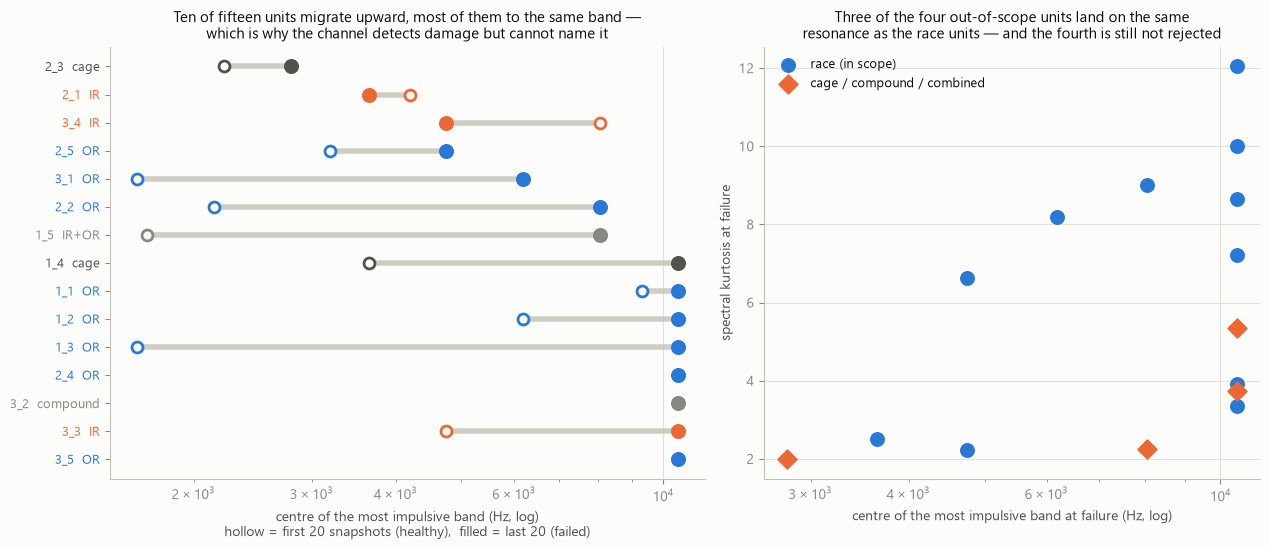

10 of 15 units move to a higher resonance band as they fail; median start 4197 Hz -> end 10512 Hz
spectral kurtosis rises on 10 of 15 (median 1.7 -> 5.3)

at failure: race units span 3644-10512 Hz; 3 of 4 out-of-scope units land inside that range
  the exception is Bearing2_3 (cage) at 2796 Hz, BELOW the race range -- separable on this one feature, and still rejected on only 3.6% of its snapshots
Bearing1_4 (cage, silent at every order): 3644 -> 10512 Hz, kurtosis 0.8 -> 5.3 -- the channel sees it, but so does every race unit


,fault,start,end,sk0,sk1
unit,,,,,
2_3,cage,2221,2796,1.0,2.0
2_1,IR,4197,3644,0.8,2.5
3_4,IR,8066,4749,5.7,6.6
2_5,OR,3198,4749,3.8,2.2
3_1,OR,1646,6189,1.7,8.2
2_2,OR,2146,8066,1.0,9.0
1_5,IR+OR,1705,8066,1.0,2.3
1_4,cage,3644,10512,0.8,5.3
1_1,OR,9289,10512,10.2,7.2


In [5]:
mig = []
for b in BEAR:
    s = G[b].sort_values("Snapshot")
    a, z = s.head(20), s.tail(20)
    mig.append(dict(unit=b.replace("Bearing", ""), fault=FAULT[b],
                    start=a["H_SKband"].median(), end=z["H_SKband"].median(),
                    sk0=a["H_SKmax"].median(), sk1=z["H_SKmax"].median()))
M = pd.DataFrame(mig).sort_values("end")

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.8, 5.6),
                               gridspec_kw=dict(width_ratios=[1.2, 1]))
CF = {"OR": C_BLUE, "IR": C_ORANGE, "cage": INK2, "IR+OR": MUTED, "compound": MUTED}
y = np.arange(len(M))
for i, r in enumerate(M.itertuples()):
    axa.plot([r.start, r.end], [i, i], color=BASE, lw=4, alpha=0.8,
             solid_capstyle="round", zorder=2)
    axa.scatter([r.start], [i], s=62, facecolors=SURFACE, edgecolors=CF[r.fault],
                linewidths=2.0, zorder=4)
    axa.scatter([r.end], [i], s=96, color=CF[r.fault], zorder=5)
axa.set_yticks(y, [f"{r.unit}  {r.fault}" for r in M.itertuples()], fontsize=9)
for i, r in enumerate(M.itertuples()):
    axa.get_yticklabels()[i].set_color(CF[r.fault])
axa.invert_yaxis()
axa.set_xscale("log")
axa.set_xlabel("centre of the most impulsive band (Hz, log)\n"
               "hollow = first 20 snapshots (healthy),  filled = last 20 (failed)")
axa.grid(axis="y", visible=False)
axa.set_title("Ten of fifteen units migrate upward, most of them to the same band —\n"
              "which is why the channel detects damage but cannot name it", fontsize=11)

grp = M.copy()
grp["scope"] = np.where(grp["fault"].isin(["OR", "IR"]), "race (in scope)",
                        "cage / compound / combined")
for sc, mk, col in (("race (in scope)", "o", C_BLUE),
                    ("cage / compound / combined", "D", C_ORANGE)):
    s = grp[grp["scope"] == sc]
    axb.scatter(s["end"], s["sk1"], s=95, marker=mk, color=col, zorder=4, label=sc)
axb.set_xscale("log")
axb.set_xlabel("centre of the most impulsive band at failure (Hz, log)")
axb.set_ylabel("spectral kurtosis at failure")
axb.legend(fontsize=9, loc="upper left")
axb.set_title("Three of the four out-of-scope units land on the same\n"
              "resonance as the race units — and the fourth is still not rejected",
              fontsize=11)
plt.tight_layout()
plt.show()

up = (M["end"] > M["start"]).sum()
print(f"{up} of 15 units move to a higher resonance band as they fail; "
      f"median start {M['start'].median():.0f} Hz -> end {M['end'].median():.0f} Hz")
print(f"spectral kurtosis rises on {(M['sk1'] > M['sk0']).sum()} of 15 "
      f"(median {M['sk0'].median():.1f} -> {M['sk1'].median():.1f})")
r = M[M["fault"].isin(["OR", "IR"])]
o = M[~M["fault"].isin(["OR", "IR"])]
inside = ((o["end"] >= r["end"].min()) & (o["end"] <= r["end"].max())).sum()
print(f"\nat failure: race units span {r['end'].min():.0f}-{r['end'].max():.0f} Hz; "
      f"{inside} of {len(o)} out-of-scope units land inside that range")
low = o[o["end"] < r["end"].min()]
for t in low.itertuples():
    print(f"  the exception is Bearing{t.unit} ({t.fault}) at {t.end:.0f} Hz, BELOW the race "
          f"range -- separable on this one feature, and still rejected on only "
          f"{max(perunit['Bearing' + t.unit].values()):.1%} of its snapshots")
print(f"Bearing1_4 (cage, silent at every order): {M[M['unit'] == '1_4']['start'].iloc[0]:.0f} "
      f"-> {M[M['unit'] == '1_4']['end'].iloc[0]:.0f} Hz, "
      f"kurtosis {M[M['unit'] == '1_4']['sk0'].iloc[0]:.1f} -> "
      f"{M[M['unit'] == '1_4']['sk1'].iloc[0]:.1f} -- the channel sees it, "
      f"but so does every race unit")
M.set_index("unit").style.format({"start": "{:.0f}", "end": "{:.0f}",
                                  "sk0": "{:.1f}", "sk1": "{:.1f}"})

**Ten of fifteen units migrate upward, from a median 4.2 kHz to 10.5 kHz, and
spectral kurtosis rises on the same ten, from a median 1.7 to 5.3.** Whatever the
fault element, a failing bearing tends to start exciting a high-frequency
structural resonance, and two thirds of the fleet ends on the *same* one. That
single fact produces all three of this notebook's results.

It is a **detection** signal, because the migration separates a unit's own
healthy start from its own failed end — which is why KA15, silent at BPFO but
ringing the structure, is finally caught.

It is **not an attribution** signal, because inner race and outer race migrate to
the same place. Adding it to the geometry features tells the forest nothing
about which race, and costs it splits it was using productively.

It is **not a rejection** signal, and the right panel shows why in two different
ways. **Three of the four out-of-scope units land inside the race units' range**
— Bearing1_4 moves 3.6 → 10.5 kHz with kurtosis 0.8 → 5.3, which is an
unambiguous damage signal and an entirely ordinary one. That is notebook 15's
central finding — *the out-of-scope units are not out of distribution* —
reproduced in a feature family chosen specifically to escape it, which is
stronger evidence for it than notebook 15 could provide alone.

The fourth unit makes a separate point that is worth more than the first.
**Bearing2_3 ends at 2.8 kHz, below every race unit**, so on this one feature it
*is* separable — and it is still rejected on only **3.6 %** of its snapshots. A
single discriminating coordinate does not survive a Mahalanobis or
nearest-neighbour rule over twenty dimensions referenced to the unit's own
baseline. The reject option fails here not only because the physics is
unfavourable but because the rules dilute the one feature that would work, which
is a modelling problem and therefore, unlike the rest of this notebook, possibly
fixable.

## What this changes

1. **The non-geometry channel delivers on one of the three lines that demanded
   it.** Detection: yes, and it rescues a bearing invisible since notebook 06.
   Attribution: no, and it is actively harmful. Reject option: no, and the
   ceiling does not move by a thousandth.
2. **KA15 is detected for the first time in this project: 0 % → 60 % of runs.**
   It is the only bearing the non-geometry channel finds that the order bands do
   not, and notebook 12's physical prediction — a dent rings the structure
   without ringing at a bearing frequency — is confirmed.
3. **KA22 is still not detected, by either channel.** Notebook 07's
   healthy-baseline anomaly score (60.2 % of recordings) remains the only thing
   in this project that has ever caught it. Half of notebook 12's open item
   closes; half does not.
4. **The two channels are complementary, not ordered, and the union is the
   cheapest detection gain available.** Non-geometry alone is the weaker
   detector (6 of 11 bearings against 7), but they disagree in both directions —
   KA15 only non-geometry, KI04 and KI21 only order bands — so **either-channel
   alarming reaches 8 of 11**, better than either family alone anywhere in this
   project. It needs no new data and no twin.
5. **Attribution degrades: 94.1 % → 90.2 % of snapshots, and the first fifth of
   inner race 38.4 % → 18.4 %.** The bin notebook 17 needed rescued is made about
   twice as wrong, and outer race loses its perfect start (100 % → 87.5 %). On
   its own the channel reaches 64.3 % and 7 of 11 units. *Which race* is
   intrinsically a geometry question and non-geometry features cannot answer it.
6. **The reject ceiling is 0.660 — identical to notebook 15's best over sixteen
   combinations**, reached here by a completely different feature family.
   Combining the two families is worse than either (0.597, 0.612). Bearing1_4,
   the unit this channel was built for, is rejected on **1.4 %** of its
   snapshots.
7. **One mechanism explains all three.** Ten of fifteen units migrate to a higher
   resonance as they fail (median 4.2 → 10.5 kHz), kurtosis rising on the same ten
   (1.7 → 5.3). Two thirds of the fleet ends on the *same* resonance, so the
   migration separates a unit's healthy start from its failed end (detection) and
   not one damage type from another (attribution, rejection). Three of the four
   out-of-scope units land inside the race units' range.
8. **A separable feature is not a usable rule.** Bearing2_3 ends at 2.8 kHz,
   below every race unit, so it *is* separable on `SKband` alone — and it is
   still rejected on only **3.6 %** of snapshots, because one discriminating
   coordinate does not survive a distance rule over twenty dimensions. That part
   of the reject failure is a modelling problem, not a physical one.
9. **Notebook 15's central claim is independently corroborated.** *The
   out-of-scope units are not out of distribution* was diagnosed from
   bearing-geometry features; it reproduces in a feature family chosen
   specifically to escape geometry. That makes it a property of the failures,
   not of the feature choice — which is a materially stronger statement than
   notebook 15 could make.
10. **A lead, not a result:** Bearing3_2 (compound) is rejected on **36.5 %** of
   snapshots by the one-class forest, against 0–2.3 % for every out-of-scope unit
   in notebook 15. One unit on one rule, and rejection is least clearly the right
   answer for a compound fault — but it is the only out-of-scope unit any feature
   family here has moved.